# Infinite-width Gaussian-RBF kernel solve on the 5-petal domain

This notebook uses the **same flower geometry and manufactured field** as the
supplied MATLAB example, but replaces its finite-center RBF/KAPI-ELM solve with
our **exact infinite-width Gaussian-RBF kernel collocation method** and
**null-space Dirichlet enforcement**.

Geometry:
\[
r_b(\theta)=0.33+0.10\cos(5\theta),
\]
centered at \((0.5,0.5)\).

Manufactured solution:
\[
u_{\rm ex}(x,y)=\sin(4\pi x)\cos(4\pi y).
\]

Our kernel operator is \(L=-\Delta\), therefore
\[
-\Delta u_{\rm ex}=(k_x^2+k_y^2)u_{\rm ex}.
\]

Boundary data are the exact nonzero Dirichlet values of this manufactured field
on the flower boundary.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import svd
from time import perf_counter


In [2]:
import numpy as np
from scipy.special import erf

def radical_inverse_scalar(n, b):
    r = 0.0
    f = 1.0 / b
    while n > 0:
        r += f * (n % b)
        n //= b
        f /= b
    return r

def flower_radius(theta, R0=0.33, A=0.10, n_petals=5):
    theta = np.asarray(theta, dtype=float)
    return R0 + A*np.cos(n_petals*theta)

def flower_inside(x, y, cx=0.5, cy=0.5, R0=0.33, A=0.10, n_petals=5):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    dx = x - cx
    dy = y - cy
    rr = np.hypot(dx, dy)
    th = np.arctan2(dy, dx)
    return rr <= flower_radius(th, R0, A, n_petals)

def halton_flower(N, skip=0, cx=0.5, cy=0.5, R0=0.33, A=0.10, n_petals=5):
    x = np.zeros(N)
    y = np.zeros(N)
    count = 0
    idx = skip + 1
    while count < N:
        xx = radical_inverse_scalar(idx, 2)
        yy = radical_inverse_scalar(idx, 3)
        if flower_inside(xx, yy, cx, cy, R0, A, n_petals):
            x[count] = xx
            y[count] = yy
            count += 1
        idx += 1
    return x, y

def rbf1d_uniform_derivs_full(x, y, sigma, ca, cb):
    x = np.asarray(x, dtype=float).reshape(-1, 1)
    y = np.asarray(y, dtype=float).reshape(1, -1)
    m = 0.5*(x+y)
    d = x-y
    A = 0.5*d
    za = ca-m
    zb = cb-m

    Ed = np.exp(-(d**2)/(4*sigma**2))
    ea = np.exp(-(za/sigma)**2)
    eb = np.exp(-(zb/sigma)**2)
    E = erf(zb/sigma)-erf(za/sigma)

    J0 = 0.5*sigma*np.sqrt(np.pi)*E
    J1 = 0.5*sigma**2*(ea-eb)
    J2 = 0.25*sigma**3*np.sqrt(np.pi)*E - 0.5*sigma**2*(zb*eb-za*ea)
    J3 = -0.5*sigma**2*(zb**2*eb-za**2*ea) + sigma**2*J1
    J4 = -0.5*sigma**2*(zb**3*eb-za**3*ea) + 1.5*sigma**2*J2

    C = 1/(cb-ca)
    F = C*Ed

    Iq = A*J0-J1
    Ir = -A*J0-J1
    Iq2 = A**2*J0-2*A*J1+J2
    Ir2 = A**2*J0+2*A*J1+J2
    Iqr = J2-A**2*J0
    Iq2r = -A**3*J0+A**2*J1+A*J2-J3
    Iqr2 = A**3*J0+A**2*J1-A*J2-J3
    Iq2r2 = A**4*J0-2*A**2*J2+J4

    K = F*J0
    K1 = -F*Iq/sigma**2
    K2 = -F*Ir/sigma**2
    K11 = F*(Iq2/sigma**4-J0/sigma**2)
    K22 = F*(Ir2/sigma**4-J0/sigma**2)
    K12 = F*Iqr/sigma**4
    K112 = F*(-Iq2r/sigma**6+Ir/sigma**4)
    K122 = F*(-Iqr2/sigma**6+Iq/sigma**4)
    K1122 = F*(Iq2r2/sigma**8-(Iq2+Ir2)/sigma**6+J0/sigma**4)
    return K,K1,K2,K11,K22,K12,K112,K122,K1122

def compute_kernel_norm(cfg):
    xr = 0.5*(cfg["c_a"] + cfg["c_b"])
    K0 = rbf1d_uniform_derivs_full(
        [xr], [xr], cfg["sigma"], cfg["c_a"], cfg["c_b"]
    )[0]
    return float((K0*K0)[0,0])

def kernel_2d_poisson(cfg, x1, y1, x2, y2, type1, type2):
    """
    Infinite-width separable Gaussian-RBF kernel with L=-Delta.
    """
    Kx,_,_,Kx11,Kx22,_,_,_,Kx1122 = rbf1d_uniform_derivs_full(
        x1,x2,cfg["sigma"],cfg["c_a"],cfg["c_b"]
    )
    Ky,_,_,Ky11,Ky22,_,_,_,Ky1122 = rbf1d_uniform_derivs_full(
        y1,y2,cfg["sigma"],cfg["c_a"],cfg["c_b"]
    )

    if type1=="val" and type2=="val":
        K = Kx*Ky
    elif type1=="pde" and type2=="val":
        K = -(Kx11*Ky + Kx*Ky11)
    elif type1=="val" and type2=="pde":
        K = -(Kx22*Ky + Kx*Ky22)
    elif type1=="pde" and type2=="pde":
        K = Kx1122*Ky + Kx11*Ky22 + Kx22*Ky11 + Kx*Ky1122
    else:
        raise ValueError("Unknown kernel functional type.")
    return K/cfg["norm_const"]

def predict_value(cfg,alpha,xP,yP,xB,yB,xq,yq,batch=800):
    xq=np.asarray(xq,float).ravel()
    yq=np.asarray(yq,float).ravel()
    uq=np.zeros_like(xq)
    for i1 in range(0,len(xq),batch):
        ids=slice(i1,min(i1+batch,len(xq)))
        KqP=kernel_2d_poisson(cfg,xq[ids],yq[ids],xP,yP,"val","pde")
        KqB=kernel_2d_poisson(cfg,xq[ids],yq[ids],xB,yB,"val","val")
        uq[ids]=np.hstack([KqP,KqB])@alpha
    return uq

def predict_pde(cfg,alpha,xP,yP,xB,yB,xq,yq,batch=500):
    xq=np.asarray(xq,float).ravel()
    yq=np.asarray(yq,float).ravel()
    Lq=np.zeros_like(xq)
    for i1 in range(0,len(xq),batch):
        ids=slice(i1,min(i1+batch,len(xq)))
        KqP=kernel_2d_poisson(cfg,xq[ids],yq[ids],xP,yP,"pde","pde")
        KqB=kernel_2d_poisson(cfg,xq[ids],yq[ids],xB,yB,"pde","val")
        Lq[ids]=np.hstack([KqP,KqB])@alpha
    return Lq

In [3]:
# ------------------------------ problem ---------------------------------
cx, cy = 0.5, 0.5
R0 = 0.33
A = 0.10
n_petals = 5

kx = 4*np.pi
ky = 4*np.pi

def uexact(x,y):
    x=np.asarray(x,float)
    y=np.asarray(y,float)
    return np.sin(kx*x)*np.cos(ky*y)

def ffun(x,y):
    return (kx**2 + ky**2)*uexact(x,y)   # for L=-Delta

# Collocation / validation counts
Np = 400+400
Nb = 140+200
Ntest = 6000
Nres = 4000
Nb_dense = 1200

# Infinite-width kernel settings
sigma = 0.075
pad = 0.18
c_a = -pad
c_b = 1.0 + pad
ridge_rel = 1e-12

# ------------------------ deterministic point sets ----------------------
xP,yP = halton_flower(Np,0,cx,cy,R0,A,n_petals)

thetaB = np.arange(Nb)*(2*np.pi/Nb)
rB = flower_radius(thetaB,R0,A,n_petals)
xB = cx + rB*np.cos(thetaB)
yB = cy + rB*np.sin(thetaB)
uB = uexact(xB,yB)

xT,yT = halton_flower(Ntest,100000,cx,cy,R0,A,n_petals)
xR,yR = halton_flower(Nres,200000,cx,cy,R0,A,n_petals)

thetaBd = np.arange(Nb_dense)*(2*np.pi/Nb_dense)
rBd = flower_radius(thetaBd,R0,A,n_petals)
xBd = cx + rBd*np.cos(thetaBd)
yBd = cy + rBd*np.sin(thetaBd)

cfg={"sigma":sigma,"c_a":c_a,"c_b":c_b}
cfg["norm_const"]=compute_kernel_norm(cfg)

print("INFINITE-RBF KERNEL SOLVE ON 5-PETAL DOMAIN")
print(f"PDE points                  = {Np}")
print(f"Boundary points             = {Nb}")
print(f"Gaussian sigma              = {sigma:.4f}")
print(f"Flower geometry             = r(theta)={R0:.2f}+{A:.2f} cos(5 theta)")
print(f"Center-support square       = [{c_a:.2f}, {c_b:.2f}]^2")

INFINITE-RBF KERNEL SOLVE ON 5-PETAL DOMAIN
PDE points                  = 800
Boundary points             = 340
Gaussian sigma              = 0.0750
Flower geometry             = r(theta)=0.33+0.10 cos(5 theta)
Center-support square       = [-0.18, 1.18]^2


In [4]:
# ---------------- kernel matrices / boundary null space -----------------
_t_solve_total0 = perf_counter()
_t0 = perf_counter()
K_BP=kernel_2d_poisson(cfg,xB,yB,xP,yP,"val","pde")
K_BB=kernel_2d_poisson(cfg,xB,yB,xB,yB,"val","val")
Bmat=np.hstack([K_BP,K_BB])

K_PP=kernel_2d_poisson(cfg,xP,yP,xP,yP,"pde","pde")
K_PB=kernel_2d_poisson(cfg,xP,yP,xB,yB,"pde","val")
Amat=np.hstack([K_PP,K_PB])
rhsP=ffun(xP,yP)
t_kernel_assembly = perf_counter() - _t0

_t0 = perf_counter()

# Minimum-norm particular solution satisfies the nonzero Dirichlet data.
alpha_p=np.linalg.pinv(Bmat,rcond=1e-13)@uB

# Complete right null space of Bmat.
Ub,sB,Vhb=svd(Bmat,full_matrices=True)
if sB.size==0:
    raise RuntimeError("Boundary matrix has no singular values.")

tolB=max(Bmat.shape)*np.finfo(float).eps*np.max(sB)
rankB=int(np.sum(sB>tolB))
Vb=Vhb.T
Q=Vb[:,rankB:]

t_nullspace = perf_counter() - _t0

print(f"Boundary matrix size        = {Bmat.shape[0]} x {Bmat.shape[1]}")
print(f"Numerical boundary rank     = {rankB}")
print(f"Null-space dimension        = {Q.shape[1]}")
print(f"||B Q||_F                   = {np.linalg.norm(Bmat@Q):.3e}")
print(f"Particular BC error         = {np.max(np.abs(Bmat@alpha_p-uB)):.3e}")
print(f"kernel/operator assembly time = {t_kernel_assembly:.6f} s")
print(f"constraint/null-space time   = {t_nullspace:.6f} s")


Boundary matrix size        = 340 x 1140
Numerical boundary rank     = 140
Null-space dimension        = 1000
||B Q||_F                   = 1.369e-09
Particular BC error         = 2.232e-05
kernel/operator assembly time = 0.342947 s
constraint/null-space time   = 0.173915 s


In [5]:
# ------------------------ reduced PDE solve -----------------------------
_t0 = perf_counter()
Ared=Amat@Q
bred=rhsP-Amat@alpha_p

Ua,sa,Vha=svd(Ared,full_matrices=False)
if sa.size==0 or np.max(sa)<=0:
    raise RuntimeError("Reduced PDE matrix is numerically singular on the retained scale.")

lam=ridge_rel*sa[0]**2
filt=sa/(sa**2+lam)
eta=Vha.T@(filt*(Ua.T@bred))
alpha=alpha_p+Q@eta

t_reduced_solve = perf_counter() - _t0
t_total_solve = perf_counter() - _t_solve_total0

print(f"Reduced PDE system          = {Ared.shape[0]} x {Ared.shape[1]}")
print(f"Reduced ridge lambda        = {lam:.3e}")
print(f"reduced SVD/solve time       = {t_reduced_solve:.6f} s")
print(f"total assembly+solve time    = {t_total_solve:.6f} s")


Reduced PDE system          = 800 x 1000
Reduced ridge lambda        = 6.254e-02
reduced SVD/solve time       = 0.309680 s
total assembly+solve time    = 0.841822 s


In [6]:
# ------------------------------ diagnostics -----------------------------
_t0 = perf_counter()
uT=predict_value(cfg,alpha,xP,yP,xB,yB,xT,yT,800)
uT_exact=uexact(xT,yT)
errT=uT-uT_exact
rmse=np.sqrt(np.mean(errT**2))
max_error=np.max(np.abs(errT))

uB_fit=Bmat@alpha
bc_train_max=np.max(np.abs(uB_fit-uB))

uBd=predict_value(cfg,alpha,xP,yP,xB,yB,xBd,yBd,800)
uBd_exact=uexact(xBd,yBd)
bc_dense_max=np.max(np.abs(uBd-uBd_exact))

LuR=predict_pde(cfg,alpha,xP,yP,xB,yB,xR,yR,500)
resR=LuR-ffun(xR,yR)
res_rms=np.sqrt(np.mean(resR**2))
res_max=np.max(np.abs(resR))
t_prediction = perf_counter() - _t0

print(f"Independent solution RMSE   = {rmse:.6e}")
print(f"Independent max error       = {max_error:.6e}")
print(f"BC max error (training)     = {bc_train_max:.6e}")
print(f"BC max error (dense flower) = {bc_dense_max:.6e}")
print(f"Residual RMS (independent)  = {res_rms:.6e}")
print(f"Residual max (independent)  = {res_max:.6e}")
print(f"diagnostic prediction time   = {t_prediction:.6f} s")


Independent solution RMSE   = 4.316254e-04
Independent max error       = 2.370641e-03
BC max error (training)     = 2.231669e-05
BC max error (dense flower) = 2.231874e-05
Residual RMS (independent)  = 7.323235e-01
Residual max (independent)  = 8.793812e+00
diagnostic prediction time   = 3.985032 s


In [7]:
# ------------------------ regular grid + archive ------------------------
Nplot=220
xg=np.linspace(0,1,Nplot)
yg=np.linspace(0,1,Nplot)
Xg,Yg=np.meshgrid(xg,yg)
mask=flower_inside(Xg,Yg,cx,cy,R0,A,n_petals)

Ug=np.full_like(Xg,np.nan,dtype=float)
Ue=np.full_like(Xg,np.nan,dtype=float)
Rg=np.full_like(Xg,np.nan,dtype=float)

xq=Xg[mask]
yq=Yg[mask]
Ug[mask]=predict_value(cfg,alpha,xP,yP,xB,yB,xq,yq,600)
Ue[mask]=uexact(xq,yq)
Rg[mask]=predict_pde(cfg,alpha,xP,yP,xB,yB,xq,yq,500)-ffun(xq,yq)

theta_plot=np.linspace(0,2*np.pi,1200)
r_plot=flower_radius(theta_plot,R0,A,n_petals)
xbnd=cx+r_plot*np.cos(theta_plot)
ybnd=cy+r_plot*np.sin(theta_plot)

np.savez_compressed(
    "INF_RBF_POISSON_PETAL_SOURCE_GEOM_results.npz",
    cx=cx,cy=cy,R0=R0,A=A,n_petals=n_petals,kx=kx,ky=ky,
    Np=Np,Nb=Nb,Ntest=Ntest,Nres=Nres,Nb_dense=Nb_dense,
    sigma=sigma,pad=pad,c_a=c_a,c_b=c_b,ridge_rel=ridge_rel,
    xP=xP,yP=yP,xB=xB,yB=yB,uB=uB,xT=xT,yT=yT,xR=xR,yR=yR,
    xBd=xBd,yBd=yBd,thetaBd=thetaBd,xbnd=xbnd,ybnd=ybnd,
    alpha=alpha,alpha_p=alpha_p,Q=Q,rankB=rankB,tolB=tolB,lam=lam,
    rmse=rmse,max_error=max_error,bc_train_max=bc_train_max,
    bc_dense_max=bc_dense_max,res_rms=res_rms,res_max=res_max,
    uB_fit=uB_fit,uBd=uBd,uBd_exact=uBd_exact,
    uT=uT,uT_exact=uT_exact,errT=errT,LuR=LuR,resR=resR,
    Nplot=Nplot,xg=xg,yg=yg,Xg=Xg,Yg=Yg,mask=mask,Ug=Ug,Ue=Ue,Rg=Rg,
    t_kernel_assembly=t_kernel_assembly,t_nullspace=t_nullspace,t_reduced_solve=t_reduced_solve,t_total_solve=t_total_solve,t_prediction=t_prediction
)
print("Saved INF_RBF_POISSON_PETAL_SOURCE_GEOM_results.npz")

Saved INF_RBF_POISSON_PETAL_SOURCE_GEOM_results.npz


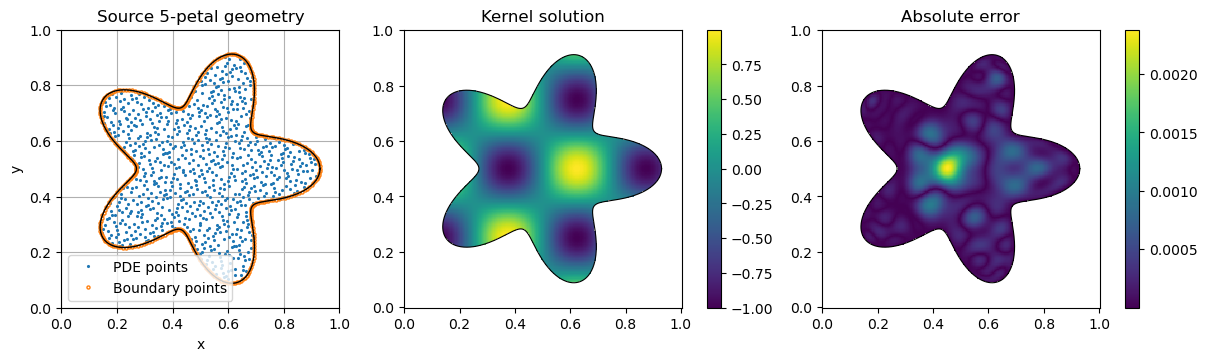

In [8]:
# Quick geometry / solution diagnostic
fig,axes=plt.subplots(1,3,figsize=(12,3.5),constrained_layout=True)

ax=axes[0]
ax.plot(xP,yP,".",ms=2.5,label="PDE points")
ax.plot(xB,yB,"o",ms=2.2,mfc="none",label="Boundary points")
ax.plot(xbnd,ybnd,"-k",lw=1.0)
ax.set_aspect("equal")
ax.set(xlim=(0,1),ylim=(0,1),xlabel="x",ylabel="y",title="Source 5-petal geometry")
ax.grid(True)
ax.legend()

im=axes[1].pcolormesh(Xg,Yg,np.ma.masked_invalid(Ug),shading="auto")
axes[1].plot(xbnd,ybnd,"-k",lw=.8)
axes[1].set_aspect("equal")
axes[1].set_title("Kernel solution")
fig.colorbar(im,ax=axes[1])

im=axes[2].pcolormesh(Xg,Yg,np.ma.masked_invalid(np.abs(Ug-Ue)),shading="auto")
axes[2].plot(xbnd,ybnd,"-k",lw=.8)
axes[2].set_aspect("equal")
axes[2].set_title("Absolute error")
fig.colorbar(im,ax=axes[2])
plt.show()